In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import (
    RunResults,
    make_accuracy_scaling_plot,
    plot_mosaic_series,
)

In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/main_text/figure_1'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS = RunResults(results_root=RESULTS_ROOT)

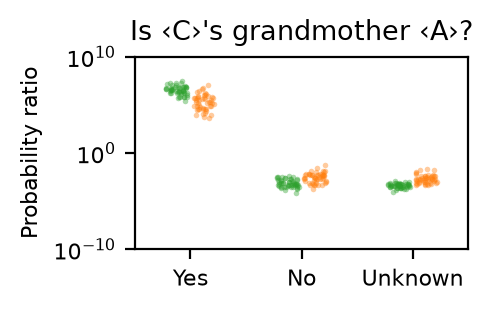

In [3]:
MODEL_PRESET = 'gemma-27b'
EXPERIMENT = 'exp_1_behavior'
STRUCTURE = 'A --fwd--> B --fwd--> C'
QUERY = 'C --grandmother--> A?'

familiar = RESULTS.load_series(
    model_preset=MODEL_PRESET,
    prompt_preset='ABC_family_tree_yes_no',
    experiment=EXPERIMENT,
    query=QUERY,
    structure=STRUCTURE,
)
synthetic = RESULTS.load_series(
    model_preset=MODEL_PRESET,
    prompt_preset='ABC_alien_family_tree_yes_no',
    experiment=EXPERIMENT,
    query=QUERY,
    structure=STRUCTURE,
)

example_plot = plot_mosaic_series(
    {
        'Domain-appropriate names': familiar,
        'Synthetic names': synthetic,
    },
    colors=['tab:green', 'tab:orange'],
    value_kind='probability_ratio',
    title="Is ‹C›'s grandmother ‹A›?"
)
if SAVE_FIGURES:
    example_plot.save(FIGURES_DIR / 'human_vs_alien_is_Cs_grandmother_A.svg')
display(example_plot.fig)
plt.close(example_plot.fig)

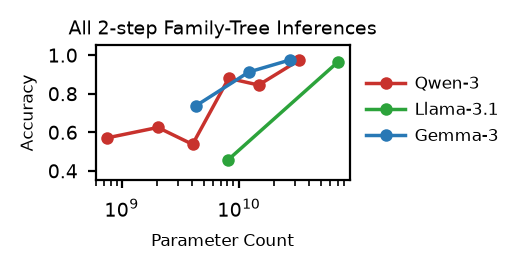

In [4]:
scaling_plot = make_accuracy_scaling_plot(
    RESULTS,
    prompt_preset='ABC_family_tree_yes_no',
    title='All 2-step Family-Tree Inferences',
)
if SAVE_FIGURES:
    scaling_plot.save(FIGURES_DIR / 'human_two_hop_accuracy.svg')

display(scaling_plot.fig)
plt.close(scaling_plot.fig)